In [1]:
%load_ext autoreload
%autoreload 2

In [25]:
import json
import sys
from pathlib import Path

project_root = Path("../../..").resolve()
sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split

from utils import DataManager, exclude_column
from utils.plotter import actual_vs_prediction, feature_importance, y_fdistro


In [4]:
COLUMNS = "bioactivity_columns.json"

In [10]:
df = DataManager(path='bioactivity/vegfr2').dataset

with open(COLUMNS, "r") as f:
    data = json.load(f)

df = df[data["columns"]]
len(df.columns)


1041

In [20]:
fp_cols = [col for col in df.columns if col.startswith("fp_")]
unique_cols = df[fp_cols].nunique()
constant_cols = unique_cols[unique_cols == 1]
# exclude_column(COLUMNS, col_name="vegfr2_exclusion", col=list(constant_cols.index))
df = df.drop(columns=constant_cols.index)

In [21]:
null = (df.isnull()).sum().sum()
len(df.columns)

1034

In [22]:
X = df.drop(columns='pIC50')
y = df['pIC50']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=25)

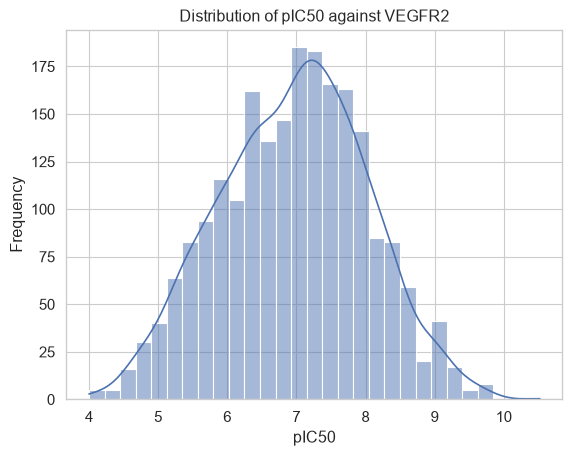

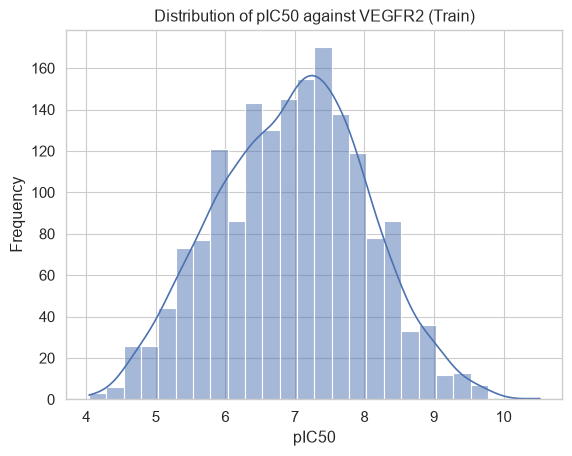

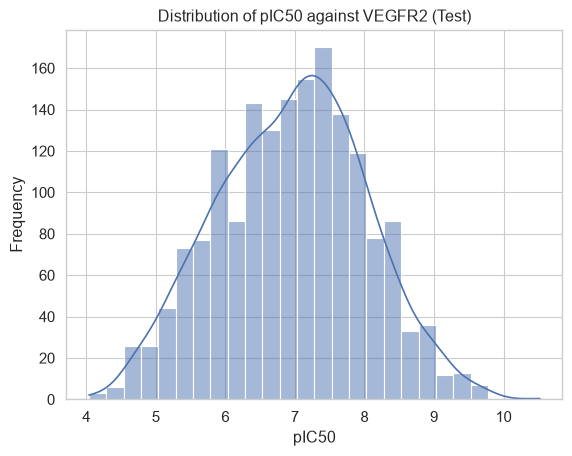

In [24]:
y_fdistro(y, "pIC50 against VEGFR2")
y_fdistro(y_train, "pIC50 against VEGFR2 (Train)")
y_fdistro(y_train, "pIC50 against VEGFR2 (Test)")

In [30]:
model = RandomForestRegressor(
    random_state=25,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [500, 1000, 1500],
    "max_depth": [None, 5, 10, 20, 30, 50],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 0.2, 0.5, 0.8, 1.0],
    "max_samples": [None, 0.6, 0.8, 1.0]
}

search = RandomizedSearchCV(
    model,
    param_distributions=param_grid,
    n_iter=50,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)
print(search.best_params_)
print(search.best_score_)



{'n_estimators': 1000, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_samples': None, 'max_features': 0.8, 'max_depth': None}
-0.6918482287503109


In [31]:
best_model = RandomForestRegressor(
    n_estimators=1000, 
    min_samples_split=2,
    min_samples_leaf=1, 
    max_features=0.8,

)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

In [33]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'RMSE: {rmse}')
print(f'MSE: {mse}')
print(f'MAE: {mae}')
print(f'R2: {r2}')


RMSE: 0.6692266493003843
MSE: 0.44786430813381956
MAE: 0.5065788707753723
R2: 0.6099198820051615


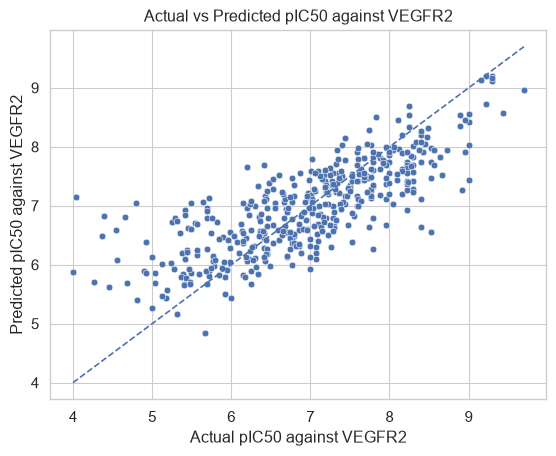

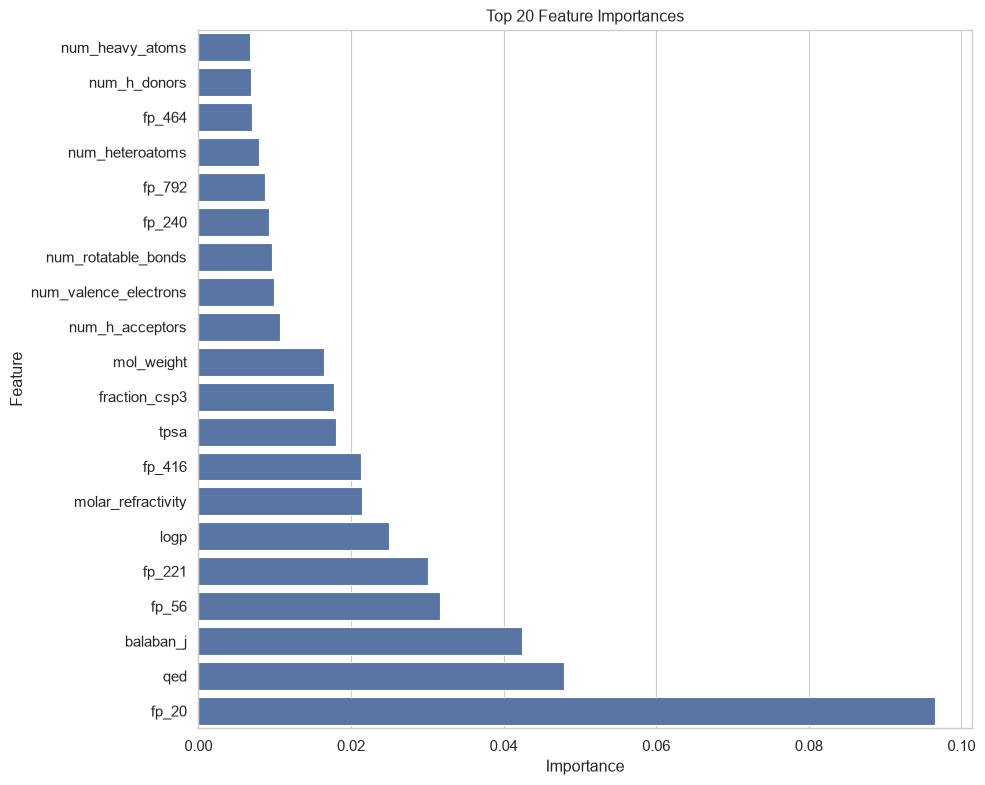

,Feature,Importance
8,num_heavy_atoms,0.006711
3,num_h_donors,0.006839
478,fp_464,0.006998
12,num_heteroatoms,0.007968
803,fp_792,0.008717
256,fp_240,0.009188
5,num_rotatable_bonds,0.009679
10,num_valence_electrons,0.009904
4,num_h_acceptors,0.010722
0,mol_weight,0.016461


In [35]:
actual_vs_prediction(y_test, y_pred, "pIC50 against VEGFR2")
feature_importance(best_model, X_train.columns)